# Red or White Wine Classifier
Logistic Regression vs ANN (TensorFlow)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

## Loading the data

In [2]:
import os

RED_FILE = 'winequality-red.csv'
WHITE_FILE = 'winequality-white.csv'
DRIVE_FOLDER = '/content/drive/MyDrive/AI projects/Wine_type_classifier/'

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

if os.path.exists(RED_FILE):
    print("Loading from local files")
    folder = ''
else:
    print("Loading from Google Drive")
    folder = DRIVE_FOLDER

# the csv files are separated with ; not ,
file_red = pd.read_csv(folder + RED_FILE, sep=';')
file_white = pd.read_csv(folder + WHITE_FILE, sep=';')

print(file_red.shape)
print(file_white.shape)

Mounted at /content/drive
Loading from Google Drive
(1599, 12)
(4898, 12)


## Red wine

In [3]:
file_red.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [4]:
file_red.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


<Axes: >

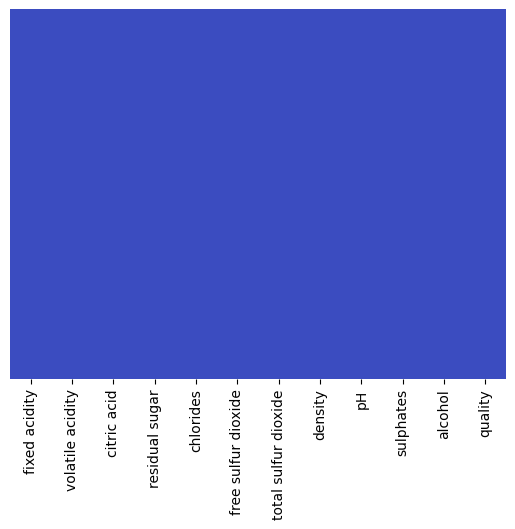

In [5]:
sns.heatmap(file_red.isnull(),yticklabels=False,cmap='coolwarm',cbar=False)

In [6]:
sns.pairplot(file_red)

Output hidden; open in https://colab.research.google.com to view.

<Axes: >

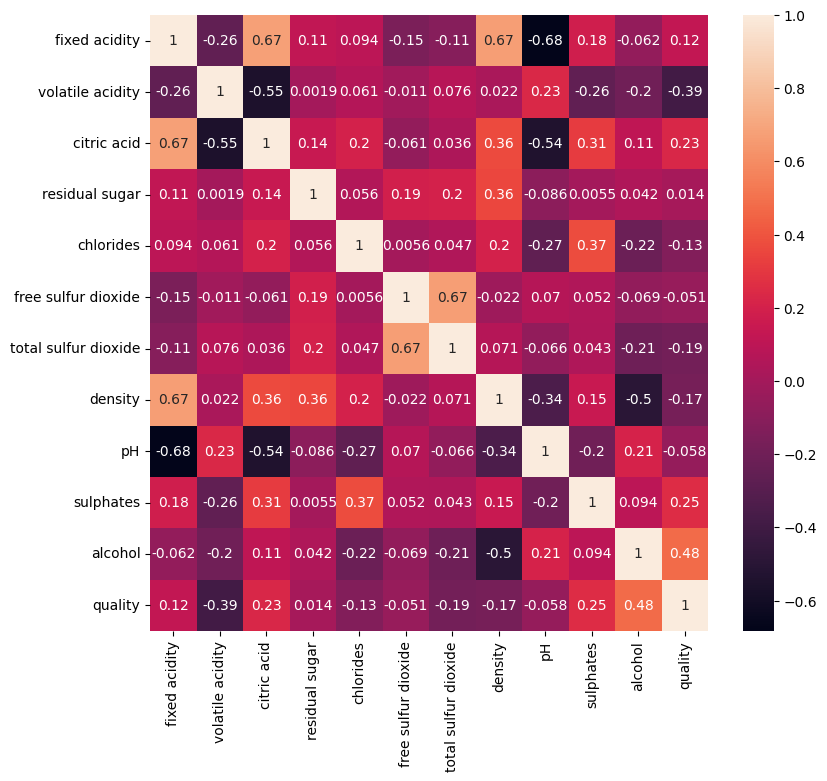

In [7]:
plt.figure(figsize=(9,8))
sns.heatmap(file_red.corr(),annot=True)

<Axes: xlabel='quality', ylabel='count'>

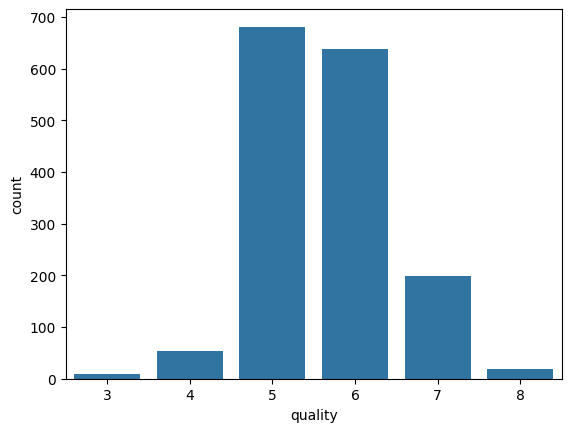

In [8]:
sns.countplot(file_red,x='quality')

In [9]:
file_red['color_red']=1
file_red

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color_red
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,1
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,1
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,1
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,1
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,1
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,1
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,1
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5,1


## White wine

In [10]:
file_white.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [11]:
file_white.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [12]:
sns.pairplot(file_white)

Output hidden; open in https://colab.research.google.com to view.

In [13]:
file_white['color_red']=0
file_white

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color_red
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.00100,3.00,0.45,8.8,6,0
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.99400,3.30,0.49,9.5,6,0
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.99510,3.26,0.44,10.1,6,0
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6,0
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.99560,3.19,0.40,9.9,6,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4893,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,0
4894,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,0
4895,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,0
4896,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,0


## Putting them together

In [14]:
wine_data=pd.concat([file_red,file_white],axis=0,ignore_index=True)
wine_data

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,color_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
6492,6.2,0.21,0.29,1.6,0.039,24.0,92.0,0.99114,3.27,0.50,11.2,6,0
6493,6.6,0.32,0.36,8.0,0.047,57.0,168.0,0.99490,3.15,0.46,9.6,5,0
6494,6.5,0.24,0.19,1.2,0.041,30.0,111.0,0.99254,2.99,0.46,9.4,6,0
6495,5.5,0.29,0.30,1.1,0.022,20.0,110.0,0.98869,3.34,0.38,12.8,7,0


In [15]:
sns.pairplot(wine_data,hue='color_red')

Output hidden; open in https://colab.research.google.com to view.

<Axes: xlabel='quality', ylabel='count'>

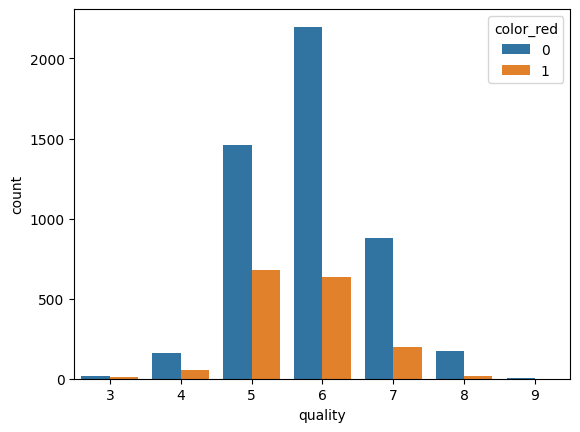

In [16]:
sns.countplot(wine_data,x='quality',hue='color_red')

In [17]:
wine_data['color_red'].value_counts()

,count
color_red,
0,4898
1,1599


## Train / test split + scaling

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [19]:
X = wine_data.drop('color_red',axis=1)
y = wine_data['color_red']

X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=101,test_size=0.25,stratify=y)

In [20]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Logistic Regression

In [21]:
from sklearn.linear_model import LogisticRegression

In [22]:
logr=LogisticRegression(max_iter=1000)
logr.fit(X_train,y_train)

LogisticRegression(max_iter=1000)

In [23]:
pred=logr.predict(X_test)

In [24]:
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [25]:
print(classification_report(y_test,pred))

              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1225
           1       0.99      0.98      0.99       400

    accuracy                           0.99      1625
   macro avg       0.99      0.99      0.99      1625
weighted avg       0.99      0.99      0.99      1625



In [26]:
confusion_matrix(y_test,pred)

array([[1222,    3],
       [   8,  392]])

## Classifying by ANN

In [27]:
import tensorflow as tf
from tensorflow import keras

tf.random.set_seed(101)

In [36]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=20, restore_best_weights=True)


tf_mlp = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid")
])

tf_mlp.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

hist_mlp = tf_mlp.fit(
    X_train, y_train,
    validation_split=0.15,
    epochs=200, batch_size=32,
    callbacks=[early_stop], verbose=0
)

tf_mlp_proba = tf_mlp.predict(X_test).ravel()
tf_mlp_pred  = (tf_mlp_proba >= 0.5).astype(int)

51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


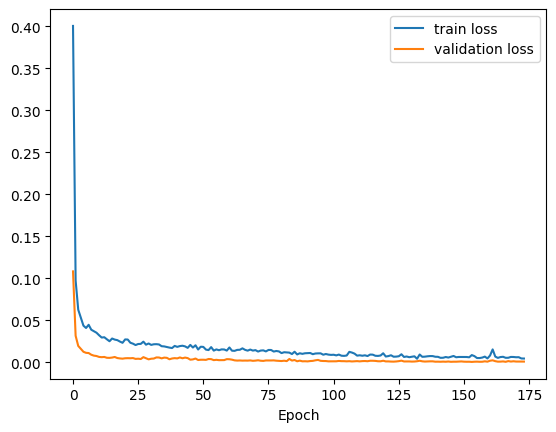

In [45]:
plt.plot(hist_mlp.history['loss'], label='train loss')
plt.plot(hist_mlp.history['val_loss'], label='validation loss')
plt.xlabel('Epoch')
plt.legend()

In [38]:
print(classification_report(y_test,tf_mlp_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1225
           1       0.99      0.99      0.99       400

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



In [39]:
confusion_matrix(y_test,tf_mlp_pred)

array([[1223,    2],
       [   3,  397]])

## Comparing the two models

In [40]:
from sklearn.metrics import accuracy_score, f1_score

print("Logistic Regression accuracy:", round(accuracy_score(y_test,pred),4))
print("ANN accuracy:", round(accuracy_score(y_test,tf_mlp_pred),4))
print()
print("Logistic Regression F1:", round(f1_score(y_test,pred),4))
print("ANN F1:", round(f1_score(y_test,tf_mlp_pred),4))

Logistic Regression accuracy: 0.9932
ANN accuracy: 0.9969

Logistic Regression F1: 0.9862
ANN F1: 0.9937


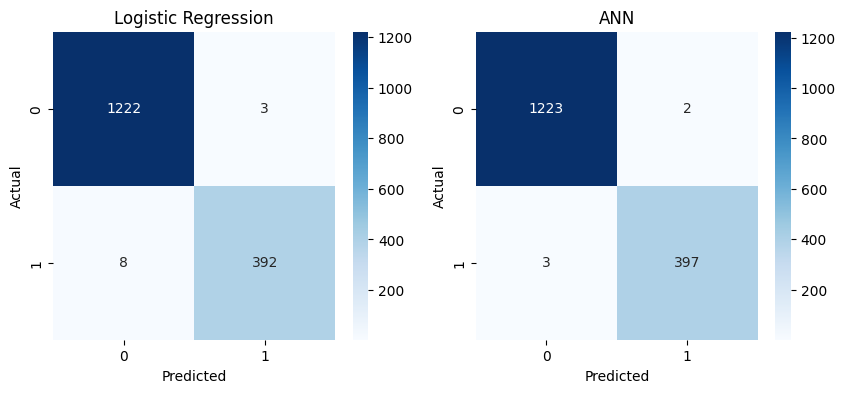

In [41]:
fig, ax = plt.subplots(1,2,figsize=(10,4))

sns.heatmap(confusion_matrix(y_test,pred),annot=True,fmt='d',cmap='Blues',ax=ax[0])
ax[0].set_title('Logistic Regression')
ax[0].set_xlabel('Predicted')
ax[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test,tf_mlp_pred),annot=True,fmt='d',cmap='Blues',ax=ax[1])
ax[1].set_title('ANN')
ax[1].set_xlabel('Predicted')
ax[1].set_ylabel('Actual')

plt.show()

## Cross validation (5 folds)

In [50]:
from sklearn.model_selection import StratifiedKFold

X_all = X.values
y_all = y.values

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=101)

lr_scores = []
ann_scores = []

for train_index, test_index in kf.split(X_all, y_all):
    X_tr, X_te = X_all[train_index], X_all[test_index]
    y_tr, y_te = y_all[train_index], y_all[test_index]

    sc = StandardScaler()
    X_tr = sc.fit_transform(X_tr)
    X_te = sc.transform(X_te)

    # logistic regression
    lr = LogisticRegression(max_iter=1000)
    lr.fit(X_tr, y_tr)
    lr_scores.append(accuracy_score(y_te, lr.predict(X_te)))

    # ANN (a new model for every fold)
    ann = keras.Sequential([
        keras.layers.Input(shape=(X_tr.shape[1],)),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(16, activation="relu"),
        keras.layers.Dense(1, activation="sigmoid")
    ])
    ann.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    ann.fit(X_tr, y_tr, validation_split=0.15, epochs=200, batch_size=32,
            callbacks=[early_stop], verbose=0)
    ann_pred = (ann.predict(X_te, verbose=0).ravel() >= 0.5).astype(int)
    ann_scores.append(accuracy_score(y_te, ann_pred))

print("Logistic Regression:", np.round(lr_scores,4))
print("ANN:                ", np.round(ann_scores,4))
print()
print(f"Logistic Regression mean: {np.mean(lr_scores):.4f} (+/- {np.std(lr_scores):.4f})")
print(f"ANN mean:                 {np.mean(ann_scores):.4f} (+/- {np.std(ann_scores):.4f})")

Logistic Regression: [0.9923 0.9923 0.9938 0.9946 0.9931]
ANN:                 [0.99   0.9854 0.9885 0.9954 0.9915]

Logistic Regression mean: 0.9932 (+/- 0.0009)
ANN mean:                 0.9902 (+/- 0.0033)


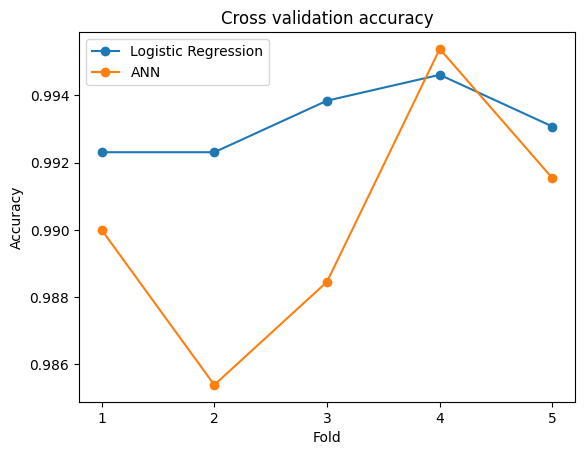

In [51]:
folds = range(1,6)
plt.plot(folds, lr_scores, marker='o', label='Logistic Regression')
plt.plot(folds, ann_scores, marker='o', label='ANN')
plt.xticks(folds)
plt.xlabel('Fold')
plt.ylabel('Accuracy')
plt.title('Cross validation accuracy')
plt.legend()
plt.show()

## Conclusion

- Both models can tell red and white wine apart really well (around 99% accuracy).
- On the single train/test split the ANN was a bit better (99.69% vs 99.32%).
- With 5-fold cross validation Logistic Regression was a bit better (99.32% vs 99.02%) and also more stable (std 0.0009 vs 0.0033).
- Logistic Regression is much simpler and faster to train, so for this dataset it is good enough. The ANN doesn't really add anything here.